# MiniBatch K-Means — Assignment-Ready Individual Model

**Model suitability**


MiniBatch K-Means is suitable because the dataset is numerical and relatively large.
It follows the K-Means idea but updates centroids using small batches, which can make clustering faster
while still producing centroid-based groups.


This notebook uses all four assigned feature datasets together.

It explicitly evaluates **multiple preprocessing / feature-engineering varieties first**.  
After one shared representation is selected, both the **Baseline** and **After** models use that exact same representation.

Therefore:

- preprocessing-variety comparison satisfies the assignment requirement;
- Baseline vs After remains fair;
- the only difference between Baseline and After is the model-specific mitigation/tuning step.

## 1. Imports and experiment settings

This cell imports the required libraries, defines FAST mode, sample sizes, cluster-balance rules, and fixed quality-gate thresholds.

In [1]:
import os, time, json, warnings, joblib, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 220)

SEED = 42
FAST = True

MODEL_SAMPLE = 2200 if FAST else 8000
HIER_SAMPLE = 900 if FAST else 4000
EVAL_SAMPLE = 700 if FAST else 2500
PLOT_SAMPLE = 1600 if FAST else 5000

MIN_SILHOUETTE = 0.25
MAX_DAVIES_BOULDIN = 1.50
MIN_ARI_STABILITY = 0.60
MIN_SMALLEST_CLUSTER_PCT = 2.0
MIN_NULL_MARGIN = 0.10

BALANCED_MIN_CLUSTER_PCT = 5.0
BALANCED_MAX_CLUSTER_PCT = 50.0
SEVERE_MIN_CLUSTER_PCT = 2.0
SEVERE_MAX_CLUSTER_PCT = 60.0

rng = np.random.default_rng(SEED)

print("FAST =", FAST)
print("MODEL_SAMPLE =", MODEL_SAMPLE)
print("HIER_SAMPLE =", HIER_SAMPLE)
print("EVAL_SAMPLE =", EVAL_SAMPLE)
print("PLOT_SAMPLE =", PLOT_SAMPLE)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-8tlkila7 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


FAST = True
MODEL_SAMPLE = 2200
HIER_SAMPLE = 900
EVAL_SAMPLE = 700
PLOT_SAMPLE = 1600


## 2. Load, clean, validate, and merge the four datasets

All four feature files are loaded, malformed rows and duplicate IDs are removed, and the datasets are merged by `image_id`.

`image_id` is not used as a model feature.

In [2]:
DATA_FILES = {
    "ColorHistogram": "ColorHistogram(6).asc",
    "ColorMoments": "ColorMoments(5).asc",
    "CoocTexture": "CoocTexture(5).asc",
    "LayoutHistogram": "LayoutHistogram(5).asc",
}
SEARCH_DIRS = [Path("."), Path("/mnt/data")]

def resolve_file(upload_name):
    for d in SEARCH_DIRS:
        p = d / upload_name
        if p.exists():
            return p
    stem = upload_name.split("(")[0].replace(".asc", "")
    for d in SEARCH_DIRS:
        matches = sorted(d.glob(stem + "*.asc"))
        if matches:
            return matches[-1]
    raise FileNotFoundError(upload_name)

def read_block(path, name):
    df = pd.read_csv(path, sep=r"\s+", header=None, engine="python", on_bad_lines="skip")
    df.columns = ["image_id"] + [f"{name}_{i}" for i in range(1, df.shape[1])]
    df["image_id"] = pd.to_numeric(df["image_id"], errors="coerce")
    feats = [c for c in df.columns if c != "image_id"]
    for c in feats:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    malformed = int(df.isna().any(axis=1).sum())
    if malformed:
        print(f"{name}: dropping {malformed} malformed rows")
    df = df.dropna().drop_duplicates("image_id").reset_index(drop=True)
    df["image_id"] = df["image_id"].astype(int)
    return df

paths = {name: resolve_file(fname) for name, fname in DATA_FILES.items()}
blocks = {name: read_block(paths[name], name) for name in DATA_FILES}

rows = []
for name, df in blocks.items():
    xb = df.drop(columns="image_id")
    rows.append({
        "Block": name,
        "Rows": len(df),
        "Features": xb.shape[1],
        "Unique_IDs": df.image_id.nunique(),
        "NaNs": int(xb.isna().sum().sum()),
        "Min": float(xb.min().min()),
        "Max": float(xb.max().max()),
        "Non_negative": bool((xb >= 0).all().all())
    })
integrity_table = pd.DataFrame(rows)
display(integrity_table)

common_ids = set.intersection(*[set(df.image_id) for df in blocks.values()])
print("Common IDs across all four datasets:", len(common_ids))

merged = None
for name in DATA_FILES:
    merged = blocks[name].copy() if merged is None else merged.merge(blocks[name], on="image_id", how="inner")
merged = merged.sort_values("image_id").reset_index(drop=True)

image_ids = merged["image_id"].copy()
feature_df = merged.drop(columns="image_id").astype(float)
X_all = feature_df.to_numpy()

block_slices = {}
start = 0
for name in DATA_FILES:
    n = len([c for c in feature_df.columns if c.startswith(name + "_")])
    block_slices[name] = slice(start, start+n)
    start += n

print("Merged shape:", merged.shape)
print("Model feature count:", X_all.shape[1])
print("Block slices:", block_slices)

,Block,Rows,Features,Unique_IDs,NaNs,Min,Max,Non_negative
0,ColorHistogram,68040,32,68040,0,0.000000,1.000104,True
1,ColorMoments,68040,9,68040,0,-4.591743,4.151256,False
2,CoocTexture,68040,16,68040,0,-5.717304,50.214500,False
3,LayoutHistogram,66615,32,66615,0,0.000000,0.250026,True


Common IDs across all four datasets: 66615
Merged shape: (66615, 90)
Model feature count: 89
Block slices: {'ColorHistogram': slice(0, 32, None), 'ColorMoments': slice(32, 41, None), 'CoocTexture': slice(41, 57, None), 'LayoutHistogram': slice(57, 89, None)}


## 3. Exploratory Data Analysis

EDA checks feature scale, zeros, negative values, outliers, and correlations for each feature block.

Histograms help explain why preprocessing and feature engineering are needed before clustering.

,Block,Features,Mean_abs,Mean_std,Zero_%,Negative_%,Outlier_fraction,Median_abs_corr
0,ColorHistogram,32,0.031253,0.062547,17.698200,0.000000,0.125319,0.068788
1,ColorMoments,9,0.857244,1.012560,0.000000,53.287464,0.012708,0.181217
2,CoocTexture,16,0.941537,1.165671,0.000000,58.360917,0.036901,0.693410
3,LayoutHistogram,32,0.031253,0.043664,19.040991,0.000000,0.106880,0.115465


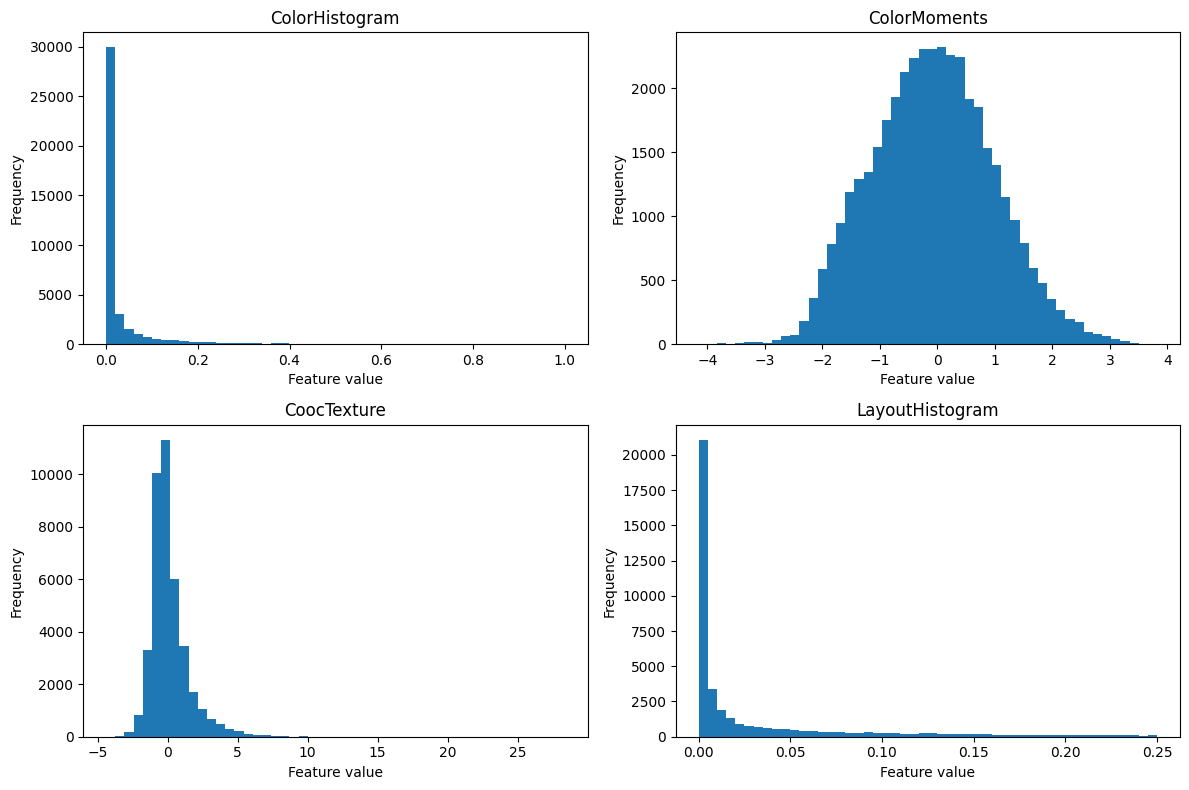

In [3]:
eda = []
for name, sl in block_slices.items():
    xb = X_all[:, sl]
    q1 = np.percentile(xb, 25, axis=0)
    q3 = np.percentile(xb, 75, axis=0)
    iqr = q3 - q1
    lo = q1 - 1.5 * iqr
    hi = q3 + 1.5 * iqr
    corr = np.corrcoef(xb, rowvar=False)
    upper = np.abs(corr[np.triu_indices_from(corr, k=1)]) if xb.shape[1] > 1 else np.array([])
    eda.append({
        "Block": name,
        "Features": xb.shape[1],
        "Mean_abs": float(np.mean(np.abs(xb))),
        "Mean_std": float(np.mean(np.std(xb, axis=0))),
        "Zero_%": float(100*np.mean(xb == 0)),
        "Negative_%": float(100*np.mean(xb < 0)),
        "Outlier_fraction": float(np.mean((xb < lo) | (xb > hi))),
        "Median_abs_corr": float(np.nanmedian(upper)) if upper.size else np.nan
    })

eda_table = pd.DataFrame(eda)
display(eda_table)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, sl) in zip(axes.ravel(), block_slices.items()):
    vals = X_all[:, sl].ravel()
    if len(vals) > 40000:
        vals = np.random.default_rng(SEED).choice(vals, 40000, replace=False)
    ax.hist(vals, bins=50)
    ax.set_title(name)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## 4. Define preprocessing varieties and evaluation tools

Three preprocessing / feature-engineering varieties are defined:

1. **Standard scaling + feature filtering**
2. **Block-balanced scaling + feature filtering**
3. **Block-balanced scaling + feature filtering + PCA(10)**

All three include 1%-99% winsorization first.

These varieties are evaluated before the Baseline-vs-After experiment. This directly demonstrates that multiple preprocessing strategies were considered.

In [4]:
def winsorize_fit_transform(X):
    lo = np.quantile(X, 0.01, axis=0)
    hi = np.quantile(X, 0.99, axis=0)
    return np.clip(X, lo, hi), {"lo": lo, "hi": hi}

def block_balance_fit_transform(X):
    parts, scalers = [], {}
    for name, sl in block_slices.items():
        sc = StandardScaler().fit(X[:, sl])
        xb = sc.transform(X[:, sl]) / np.sqrt(X[:, sl].shape[1])
        scalers[name] = sc
        parts.append(xb)
    return np.hstack(parts), {"scalers": scalers}

def feature_filter_fit_transform(X):
    var_mask = np.var(X, axis=0) > 1e-10
    Xv = X[:, var_mask]
    if Xv.shape[1] > 1:
        C = np.corrcoef(Xv, rowvar=False)
        drop = set()
        for i in range(C.shape[0]):
            if i in drop:
                continue
            for j in range(i+1, C.shape[1]):
                if abs(C[i, j]) >= 0.995:
                    drop.add(j)
        corr_keep = np.array([j for j in range(Xv.shape[1]) if j not in drop], dtype=int)
    else:
        corr_keep = np.arange(Xv.shape[1], dtype=int)
    return Xv[:, corr_keep], {"var_mask": var_mask, "corr_keep": corr_keep}

def fit_preprocessing_variant(X, variant):
    # All variants include outlier handling first.
    Xw, win_state = winsorize_fit_transform(X)

    if variant == "standard_filtered":
        scaler = StandardScaler().fit(Xw)
        Z = scaler.transform(Xw)
        Z, filt = feature_filter_fit_transform(Z)
        state = {"variant": variant, "win": win_state, "scaler": scaler, "filter": filt}
        return Z, state

    if variant == "block_balanced_filtered":
        Z, bb = block_balance_fit_transform(Xw)
        Z, filt = feature_filter_fit_transform(Z)
        state = {"variant": variant, "win": win_state, "bb": bb, "filter": filt}
        return Z, state

    if variant == "block_balanced_filtered_pca10":
        Z, bb = block_balance_fit_transform(Xw)
        Z, filt = feature_filter_fit_transform(Z)
        pca = PCA(n_components=min(10, Z.shape[1]), random_state=SEED)
        Z = pca.fit_transform(Z)
        state = {"variant": variant, "win": win_state, "bb": bb, "filter": filt, "pca": pca}
        return Z, state

    raise KeyError(variant)

PREPROCESSING_VARIANTS = [
    "standard_filtered",
    "block_balanced_filtered",
    "block_balanced_filtered_pca10",
]

def balance_metrics(labels):
    vals, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    smallest = 100 * counts.min() / counts.sum()
    largest = 100 * counts.max() / counts.sum()
    entropy = 0.0 if len(counts) < 2 else float(-(p*np.log(p)).sum()/np.log(len(counts)))

    if smallest < SEVERE_MIN_CLUSTER_PCT or largest > SEVERE_MAX_CLUSTER_PCT:
        verdict = "SEVERELY IMBALANCED"
    elif smallest >= BALANCED_MIN_CLUSTER_PCT and largest <= BALANCED_MAX_CLUSTER_PCT:
        verdict = "BALANCED"
    else:
        verdict = "MODERATELY IMBALANCED"

    return {
        "Smallest_Cluster_%": float(smallest),
        "Largest_Cluster_%": float(largest),
        "Imbalance_Ratio": float(counts.max()/max(counts.min(),1)),
        "Normalized_Entropy": entropy,
        "Balance_Verdict": verdict,
        "Cluster_Sizes": dict(zip(vals.astype(int), counts.astype(int)))
    }

def evaluate(Z, labels):
    labels = np.asarray(labels)
    k = len(np.unique(labels))
    b = balance_metrics(labels)
    out = {
        "Clusters": k,
        "Silhouette": np.nan,
        "Davies_Bouldin": np.nan,
        "Calinski_Harabasz": np.nan,
        **b
    }
    if k >= 2 and len(labels) > k:
        out["Silhouette"] = float(silhouette_score(
            Z, labels, sample_size=min(EVAL_SAMPLE, len(labels)), random_state=SEED
        ))
        out["Davies_Bouldin"] = float(davies_bouldin_score(Z, labels))
        out["Calinski_Harabasz"] = float(calinski_harabasz_score(Z, labels))
    return out

def add_average_rank(df):
    d = df.copy()
    d["Sil_Rank"] = d["Silhouette"].rank(ascending=False, method="min")
    d["DB_Rank"] = d["Davies_Bouldin"].rank(ascending=True, method="min")
    d["CH_Rank"] = d["Calinski_Harabasz"].rank(ascending=False, method="min")
    d["Average_Rank"] = d[["Sil_Rank","DB_Rank","CH_Rank"]].mean(axis=1)
    return d.sort_values(["Average_Rank","Silhouette","Davies_Bouldin"], ascending=[True,False,True])

def make_null(Z):
    mu = Z.mean(axis=0)
    cov = np.cov(Z, rowvar=False) + np.eye(Z.shape[1])*1e-6
    return np.random.default_rng(SEED+999).multivariate_normal(mu, cov, size=len(Z))

def gate_table(m, ari, margin):
    rows = [
        ("Silhouette", f">= {MIN_SILHOUETTE}", m["Silhouette"], m["Silhouette"] >= MIN_SILHOUETTE),
        ("Davies-Bouldin", f"<= {MAX_DAVIES_BOULDIN}", m["Davies_Bouldin"], m["Davies_Bouldin"] <= MAX_DAVIES_BOULDIN),
        ("ARI stability", f">= {MIN_ARI_STABILITY}", ari, ari >= MIN_ARI_STABILITY),
        ("Smallest cluster %", f">= {MIN_SMALLEST_CLUSTER_PCT}", m["Smallest_Cluster_%"], m["Smallest_Cluster_%"] >= MIN_SMALLEST_CLUSTER_PCT),
        ("Real-null Silhouette margin", f">= {MIN_NULL_MARGIN}", margin, margin >= MIN_NULL_MARGIN),
    ]
    return pd.DataFrame(rows, columns=["Criterion","Required","Actual","PASS"])

def plot_cluster_balance(before_labels, after_labels):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, labels, title in [
        (axes[0], before_labels, "Baseline cluster balance"),
        (axes[1], after_labels, "After mitigation cluster balance")
    ]:
        vals, counts = np.unique(labels, return_counts=True)
        pct = 100 * counts / counts.sum()
        ax.bar([str(v) for v in vals], pct)
        ax.set_title(title)
        ax.set_xlabel("Cluster")
        ax.set_ylabel("Percentage")
        for i, p in enumerate(pct):
            ax.text(i, p, f"{p:.1f}%", ha="center", va="bottom")
    plt.tight_layout()
    plt.show()

def plot_quality_bars(before_m, after_m, before_ari, after_ari, model_name):
    names = ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "ARI Stability"]
    b = [before_m["Silhouette"], before_m["Davies_Bouldin"], before_m["Calinski_Harabasz"], before_ari]
    a = [after_m["Silhouette"], after_m["Davies_Bouldin"], after_m["Calinski_Harabasz"], after_ari]

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    for ax, name, bv, av in zip(axes, names, b, a):
        bars = ax.bar(["Baseline", "After"], [bv, av])
        ax.set_title(name)
        ax.grid(axis="y", alpha=.25)
        for bar, val in zip(bars, [bv, av]):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{val:.3f}", ha="center", va="bottom", fontsize=9)
    plt.suptitle(f"{model_name}: Baseline vs After Mitigation")
    plt.tight_layout()
    plt.show()

def plot_2d(Z, before_labels, after_labels):
    Z2 = PCA(n_components=2, random_state=SEED).fit_transform(Z)
    n = min(PLOT_SAMPLE, len(Z2))
    ii = np.random.default_rng(SEED).choice(len(Z2), n, replace=False)
    fig, axes = plt.subplots(1,2,figsize=(12,5))
    axes[0].scatter(Z2[ii,0], Z2[ii,1], c=np.asarray(before_labels)[ii], s=8, alpha=.65)
    axes[0].set_title("Baseline clusters")
    axes[1].scatter(Z2[ii,0], Z2[ii,1], c=np.asarray(after_labels)[ii], s=8, alpha=.65)
    axes[1].set_title("After clusters")
    for ax in axes:
        ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    plt.tight_layout()
    plt.show()

## 5. Create one modelling sample

A reproducible sample is selected once. The same observations are used for preprocessing comparison, baseline training, and after-model tuning.

In [5]:
sample_n=min(MODEL_SAMPLE,len(X_all))
idx=np.random.default_rng(SEED).choice(len(X_all),sample_n,replace=False)
X_model=X_all[idx]
ids_model=image_ids.iloc[idx].reset_index(drop=True)
print("Model sample shape:",X_model.shape)

Model sample shape: (2200, 89)


## 6. Compare preprocessing / feature-engineering varieties

To satisfy the preprocessing-variety requirement fairly, each representation is tested using the same provisional MiniBatch K-Means configuration.

The varieties are compared using Silhouette, Davies-Bouldin, and Calinski-Harabasz. An average rank is used to choose the shared representation.

**Important:** after selection, both the Baseline and After models use the same selected representation.

In [6]:
def provisional_labels(Z):
    return MiniBatchKMeans(
        n_clusters=4,batch_size=256,n_init=5,max_iter=100,
        reassignment_ratio=0.01,random_state=SEED
    ).fit_predict(Z)

prep_rows=[]
prep_cache={}
prep_state_cache={}

for variant in PREPROCESSING_VARIANTS:
    Z,state=fit_preprocessing_variant(X_model,variant)
    prep_cache[variant]=Z
    prep_state_cache[variant]=state
    lab=provisional_labels(Z)
    m=evaluate(Z,lab)
    prep_rows.append({
        "Preprocessing":variant,
        "Features_after_engineering":Z.shape[1],
        "Silhouette":m["Silhouette"],
        "Davies_Bouldin":m["Davies_Bouldin"],
        "Calinski_Harabasz":m["Calinski_Harabasz"],
        "Smallest_Cluster_%":m["Smallest_Cluster_%"],
        "Balance_Verdict":m["Balance_Verdict"]
    })

preprocessing_results=pd.DataFrame(prep_rows)
preprocessing_ranked=add_average_rank(preprocessing_results)
display(preprocessing_ranked)

selected_preprocessing=preprocessing_ranked.iloc[0]["Preprocessing"]
Z_model=prep_cache[selected_preprocessing]
preprocessor_state=prep_state_cache[selected_preprocessing]

print("Selected shared preprocessing:",selected_preprocessing)
print("Shared feature matrix shape:",Z_model.shape)

,Preprocessing,Features_after_engineering,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster_%,Balance_Verdict,Sil_Rank,DB_Rank,CH_Rank,Average_Rank
2,block_balanced_filtered_pca10,10,0.118126,1.971484,265.614620,14.227273,BALANCED,1.0,1.0,1.0,1.000000
0,standard_filtered,86,0.067564,2.335104,172.790826,7.681818,MODERATELY IMBALANCED,2.0,2.0,3.0,2.333333
1,block_balanced_filtered,86,0.061349,2.577362,196.485577,13.181818,BALANCED,3.0,3.0,2.0,2.666667


Selected shared preprocessing: block_balanced_filtered_pca10
Shared feature matrix shape: (2200, 10)


## 7. Train the Baseline MiniBatch K-Means model

The Baseline uses the selected **preprocessed and feature-engineered data**, not raw data.

It uses a fixed reasonable model configuration so we can measure quality before mitigation.

In [7]:
baseline_cfg={"k":4,"batch_size":256,"n_init":5 if FAST else 10,"max_iter":100,"reassignment_ratio":0.01}
baseline_model=MiniBatchKMeans(
    n_clusters=baseline_cfg["k"],batch_size=baseline_cfg["batch_size"],
    n_init=baseline_cfg["n_init"],max_iter=baseline_cfg["max_iter"],
    reassignment_ratio=baseline_cfg["reassignment_ratio"],random_state=SEED
)
baseline_labels=baseline_model.fit_predict(Z_model)
baseline_metrics=evaluate(Z_model,baseline_labels)
display(pd.DataFrame([{k:v for k,v in baseline_metrics.items() if k!="Cluster_Sizes"}]))
print("Baseline config:",baseline_cfg)
print("Baseline balance:",baseline_metrics["Balance_Verdict"],baseline_metrics["Cluster_Sizes"])

,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster_%,Largest_Cluster_%,Imbalance_Ratio,Normalized_Entropy,Balance_Verdict
0,4,0.118126,1.971484,265.61462,14.227273,36.636364,2.57508,0.953999,BALANCED


Baseline config: {'k': 4, 'batch_size': 256, 'n_init': 5, 'max_iter': 100, 'reassignment_ratio': 0.01}
Baseline balance: BALANCED {np.int64(0): np.int64(806), np.int64(1): np.int64(313), np.int64(2): np.int64(662), np.int64(3): np.int64(419)}


## 8. Define stability and null-test functions

ARI stability measures repeatability of the cluster assignments.

The null test compares real-data clustering with Gaussian reference data. These checks are applied to both Baseline and After models.

In [8]:
def stability_ari(cfg):
    labs=[]
    for s in ([42,43] if FAST else [42,43,44]):
        mdl=MiniBatchKMeans(n_clusters=int(cfg["k"]),batch_size=int(cfg["batch_size"]),n_init=int(cfg["n_init"]),max_iter=int(cfg["max_iter"]),reassignment_ratio=float(cfg["reassignment_ratio"]),random_state=s)
        labs.append(mdl.fit_predict(Z_model))
    vals=[adjusted_rand_score(labs[i],labs[j]) for i in range(len(labs)) for j in range(i+1,len(labs))]
    return float(np.mean(vals))

def null_margin(cfg):
    mdl=MiniBatchKMeans(n_clusters=int(cfg["k"]),batch_size=int(cfg["batch_size"]),n_init=int(cfg["n_init"]),max_iter=int(cfg["max_iter"]),reassignment_ratio=float(cfg["reassignment_ratio"]),random_state=SEED)
    lab=mdl.fit_predict(Z_model); real=evaluate(Z_model,lab)["Silhouette"]
    Zn=make_null(Z_model)
    nmdl=MiniBatchKMeans(n_clusters=int(cfg["k"]),batch_size=int(cfg["batch_size"]),n_init=int(cfg["n_init"]),max_iter=int(cfg["max_iter"]),reassignment_ratio=float(cfg["reassignment_ratio"]),random_state=SEED)
    nlab=nmdl.fit_predict(Zn); ns=evaluate(Zn,nlab)["Silhouette"]
    return real,ns,real-ns

## 9. Mitigation: tune the MiniBatch K-Means model

The After model receives **the exact same engineered feature matrix** as the Baseline.

The mitigation step tests multiple model-specific hyperparameter combinations and ranks them using Silhouette, Davies-Bouldin, and Calinski-Harabasz.

In [9]:
K_VALUES=[2,3,4,5,6] if FAST else [2,3,4,5,6,7,8]
BATCH_VALUES=[128,256] if FAST else [128,256,512]
REASSIGN_VALUES=[0.01,0.05] if FAST else [0.005,0.01,0.05]
N_INIT_VALUES=[3] if FAST else [5,10]

rows=[]
for k,batch,reassign,n_init in itertools.product(K_VALUES,BATCH_VALUES,REASSIGN_VALUES,N_INIT_VALUES):
    mdl=MiniBatchKMeans(n_clusters=k,batch_size=batch,reassignment_ratio=reassign,n_init=n_init,max_iter=100,random_state=SEED)
    t0=time.perf_counter(); lab=mdl.fit_predict(Z_model); fit_time=time.perf_counter()-t0
    m=evaluate(Z_model,lab)
    rows.append({"k":k,"batch_size":batch,"reassignment_ratio":reassign,"n_init":n_init,"max_iter":100,"Fit_Time":fit_time,"Inertia":float(mdl.inertia_),**{kk:vv for kk,vv in m.items() if kk!="Cluster_Sizes"}})
results_df=pd.DataFrame(rows)
ranked_df=add_average_rank(results_df)
display(ranked_df.head(15))

,k,batch_size,reassignment_ratio,n_init,max_iter,Fit_Time,Inertia,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster_%,Largest_Cluster_%,Imbalance_Ratio,Normalized_Entropy,Balance_Verdict,Sil_Rank,DB_Rank,CH_Rank,Average_Rank
4,3,128,0.01,3,100,0.120107,4818.582975,3,0.144545,2.000303,326.862399,11.636364,45.318182,3.894531,0.884584,BALANCED,1.0,9.0,5.0,5.000000
5,3,128,0.05,3,100,0.118595,4818.582975,3,0.144545,2.000303,326.862399,11.636364,45.318182,3.894531,0.884584,BALANCED,1.0,9.0,5.0,5.000000
16,6,128,0.01,3,100,0.099995,3840.762135,6,0.142440,1.764114,276.696269,9.272727,25.454545,2.745098,0.961315,BALANCED,5.0,1.0,13.0,6.333333
17,6,128,0.05,3,100,0.127384,3840.762135,6,0.142440,1.764114,276.696269,9.272727,25.454545,2.745098,0.961315,BALANCED,5.0,1.0,13.0,6.333333
0,2,128,0.01,3,100,0.090427,5343.812311,2,0.143014,2.319505,367.371594,43.545455,56.454545,1.296451,0.987946,MODERATELY IMBALANCED,3.0,19.0,3.0,8.333333
1,2,128,0.05,3,100,0.123658,5343.812311,2,0.143014,2.319505,367.371594,43.545455,56.454545,1.296451,0.987946,MODERATELY IMBALANCED,3.0,19.0,3.0,8.333333
2,2,256,0.01,3,100,0.123895,5330.958018,2,0.140515,2.305597,372.098641,47.590909,52.409091,1.101242,0.998325,MODERATELY IMBALANCED,7.0,17.0,1.0,8.333333
3,2,256,0.05,3,100,0.101945,5330.958018,2,0.140515,2.305597,372.098641,47.590909,52.409091,1.101242,0.998325,MODERATELY IMBALANCED,7.0,17.0,1.0,8.333333
14,5,256,0.01,3,100,0.090279,4100.975103,5,0.126970,1.926557,284.598447,14.045455,27.545455,1.961165,0.971036,BALANCED,11.0,5.0,11.0,9.000000
15,5,256,0.05,3,100,0.097331,4100.975103,5,0.126970,1.926557,284.598447,14.045455,27.545455,1.961165,0.971036,BALANCED,11.0,5.0,11.0,9.000000


## 10. Select and evaluate the After model

The strongest candidates are checked using ARI stability, the null test, cluster balance, and the fixed quality gate.

If no configuration passes every threshold, the best valid ranked solution is reported honestly.

In [10]:
baseline_ari=stability_ari(baseline_cfg)
_,baseline_null,baseline_margin=null_margin(baseline_cfg)
baseline_gate=gate_table(baseline_metrics,baseline_ari,baseline_margin)

candidate_rows=[]
for _,r in ranked_df.head(min(8,len(ranked_df))).iterrows():
    cfg={"k":int(r["k"]),"batch_size":int(r["batch_size"]),"reassignment_ratio":float(r["reassignment_ratio"]),"n_init":int(r["n_init"]),"max_iter":int(r["max_iter"])}
    mdl=MiniBatchKMeans(n_clusters=cfg["k"],batch_size=cfg["batch_size"],n_init=cfg["n_init"],max_iter=cfg["max_iter"],reassignment_ratio=cfg["reassignment_ratio"],random_state=SEED)
    lab=mdl.fit_predict(Z_model); m=evaluate(Z_model,lab)
    ari=stability_ari(cfg); _,_,margin=null_margin(cfg); gt=gate_table(m,ari,margin)
    candidate_rows.append({**cfg,"Silhouette":m["Silhouette"],"Davies_Bouldin":m["Davies_Bouldin"],"Calinski_Harabasz":m["Calinski_Harabasz"],"ARI":ari,"Null_Margin":margin,"Gate_PASS":bool(gt.PASS.all())})
candidate_df=pd.DataFrame(candidate_rows)
display(candidate_df)

passing=candidate_df[candidate_df.Gate_PASS]
chosen=passing.sort_values(["Silhouette","Davies_Bouldin"],ascending=[False,True]).iloc[0] if len(passing) else ranked_df.iloc[0]
after_cfg={"k":int(chosen["k"]),"batch_size":int(chosen["batch_size"]),"reassignment_ratio":float(chosen["reassignment_ratio"]),"n_init":int(chosen["n_init"]),"max_iter":int(chosen["max_iter"])}
after_model=MiniBatchKMeans(n_clusters=after_cfg["k"],batch_size=after_cfg["batch_size"],n_init=after_cfg["n_init"],max_iter=after_cfg["max_iter"],reassignment_ratio=after_cfg["reassignment_ratio"],random_state=SEED)
after_labels=after_model.fit_predict(Z_model)
after_metrics=evaluate(Z_model,after_labels)
after_ari=stability_ari(after_cfg)
_,after_null,after_margin=null_margin(after_cfg)
after_gate=gate_table(after_metrics,after_ari,after_margin)
QUALITY_MET=bool(after_gate.PASS.all())
print("Selected after config:",after_cfg)
display(after_gate)
print("QUALITY MET" if QUALITY_MET else "QUALITY NOT FULLY MET")

,k,batch_size,reassignment_ratio,n_init,max_iter,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,Null_Margin,Gate_PASS
0,3,128,0.01,3,100,0.144545,2.000303,326.862399,0.229783,0.057598,False
1,3,128,0.05,3,100,0.144545,2.000303,326.862399,0.229783,0.057598,False
2,6,128,0.01,3,100,0.142440,1.764114,276.696269,0.394403,0.062277,False
3,6,128,0.05,3,100,0.142440,1.764114,276.696269,0.394403,0.062277,False
4,2,128,0.01,3,100,0.143014,2.319505,367.371594,0.649902,0.009191,False
5,2,128,0.05,3,100,0.143014,2.319505,367.371594,0.649902,0.009191,False
6,2,256,0.01,3,100,0.140515,2.305597,372.098641,0.143223,0.003583,False
7,2,256,0.05,3,100,0.140515,2.305597,372.098641,0.143223,0.003583,False


Selected after config: {'k': 3, 'batch_size': 128, 'reassignment_ratio': 0.01, 'n_init': 3, 'max_iter': 100}


,Criterion,Required,Actual,PASS
0,Silhouette,>= 0.25,0.144545,False
1,Davies-Bouldin,<= 1.5,2.000303,False
2,ARI stability,>= 0.6,0.229783,False
3,Smallest cluster %,>= 2.0,11.636364,True
4,Real-null Silhouette margin,>= 0.1,0.057598,False


QUALITY NOT FULLY MET


## 11. Baseline vs After quality and balance comparison

Both models are compared using the same metrics and the same data representation.

Diagrams show:
- quality metrics before and after mitigation;
- cluster balance for both models;
- 2D PCA views of both cluster assignments.

,Metric,Baseline,After,Change
0,Silhouette,0.118126,0.144545,0.026419
1,Davies_Bouldin,1.971484,2.000303,0.028819
2,Calinski_Harabasz,265.614620,326.862399,61.247779
3,ARI_Stability,0.264954,0.229783,-0.035171
4,Smallest_Cluster_%,14.227273,11.636364,-2.590909
5,Largest_Cluster_%,36.636364,45.318182,8.681818
6,Normalized_Entropy,0.953999,0.884584,-0.069416
7,Null_Margin,0.027048,0.057598,0.030550


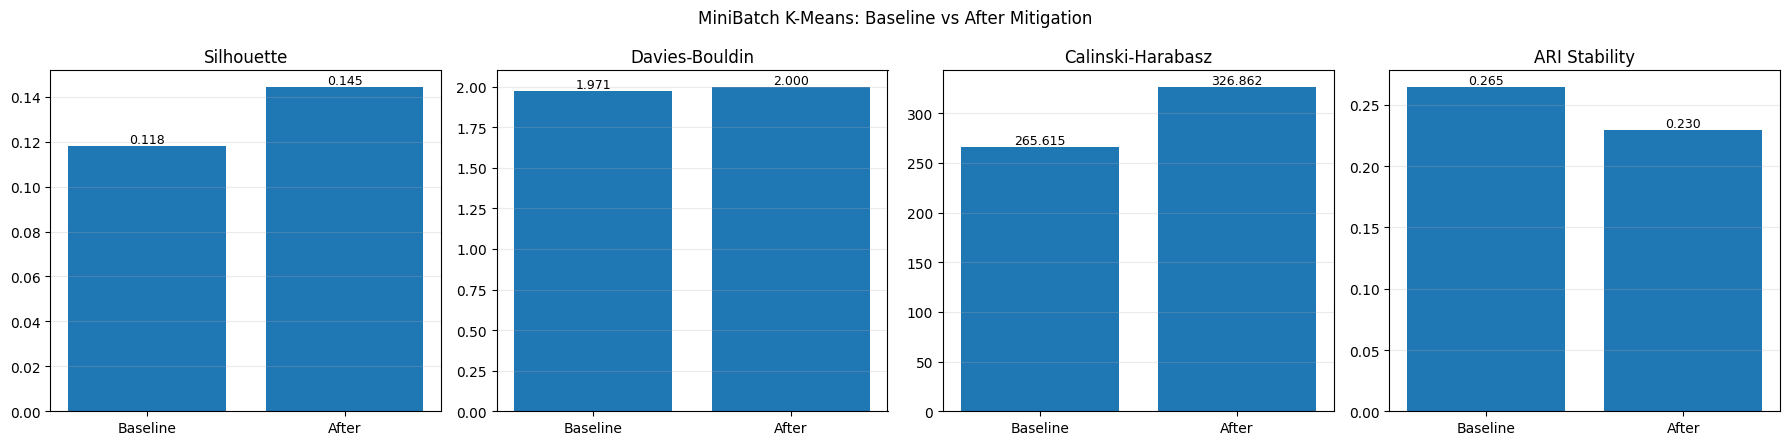

Baseline balance: BALANCED {np.int64(0): np.int64(806), np.int64(1): np.int64(313), np.int64(2): np.int64(662), np.int64(3): np.int64(419)}
After balance: BALANCED {np.int64(0): np.int64(997), np.int64(1): np.int64(256), np.int64(2): np.int64(947)}


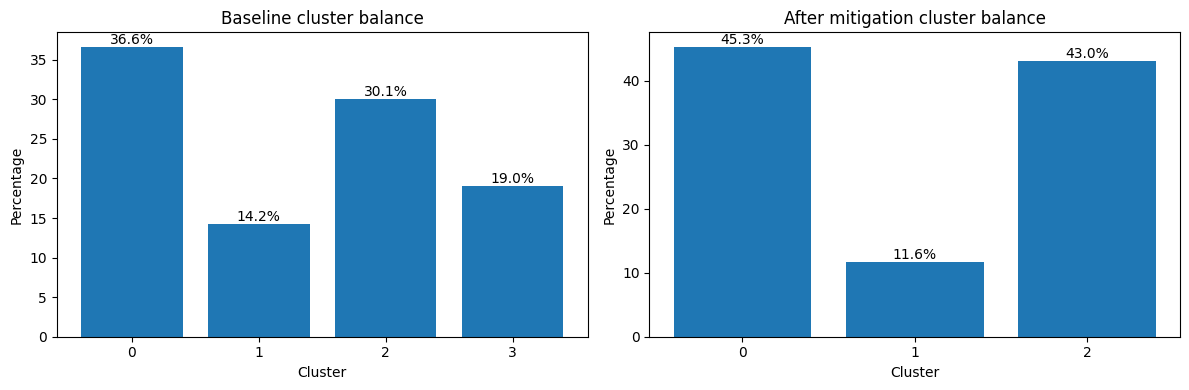

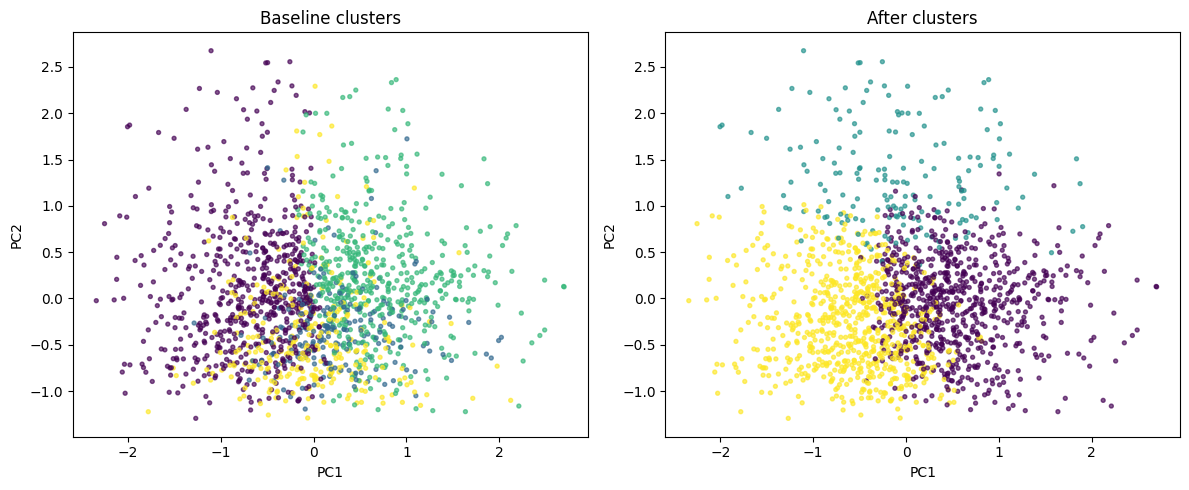

In [11]:
comparison_table=pd.DataFrame({
    "Metric":["Silhouette","Davies_Bouldin","Calinski_Harabasz","ARI_Stability","Smallest_Cluster_%","Largest_Cluster_%","Normalized_Entropy","Null_Margin"],
    "Baseline":[baseline_metrics["Silhouette"],baseline_metrics["Davies_Bouldin"],baseline_metrics["Calinski_Harabasz"],baseline_ari,baseline_metrics["Smallest_Cluster_%"],baseline_metrics["Largest_Cluster_%"],baseline_metrics["Normalized_Entropy"],baseline_margin],
    "After":[after_metrics["Silhouette"],after_metrics["Davies_Bouldin"],after_metrics["Calinski_Harabasz"],after_ari,after_metrics["Smallest_Cluster_%"],after_metrics["Largest_Cluster_%"],after_metrics["Normalized_Entropy"],after_margin]
})
comparison_table["Change"]=comparison_table["After"]-comparison_table["Baseline"]
display(comparison_table)

plot_quality_bars(baseline_metrics,after_metrics,baseline_ari,after_ari,"MiniBatch K-Means")
print("Baseline balance:",baseline_metrics["Balance_Verdict"],baseline_metrics["Cluster_Sizes"])
print("After balance:",after_metrics["Balance_Verdict"],after_metrics["Cluster_Sizes"])
plot_cluster_balance(baseline_labels,after_labels)
plot_2d(Z_model,baseline_labels,after_labels)

## 12. Diagnose performance across different cluster numbers

These diagrams show the strongest Silhouette, Davies-Bouldin, and Calinski-Harabasz values obtained for each tested `k`.

This helps explain the selected cluster number.

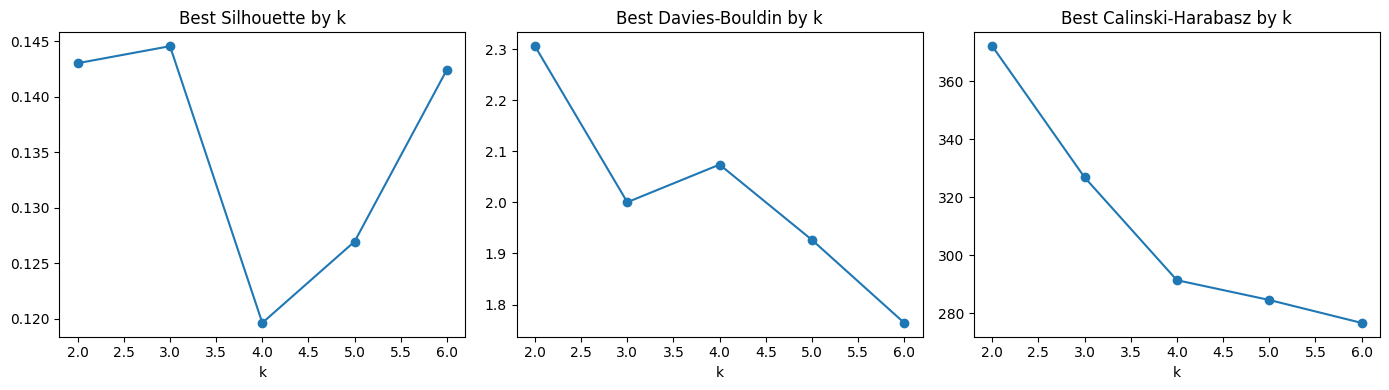

In [12]:
diag=results_df.groupby("k",as_index=False).agg({
    "Silhouette":"max",
    "Davies_Bouldin":"min",
    "Calinski_Harabasz":"max"
})
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].plot(diag.k,diag.Silhouette,marker="o"); axes[0].set_title("Best Silhouette by k")
axes[1].plot(diag.k,diag.Davies_Bouldin,marker="o"); axes[1].set_title("Best Davies-Bouldin by k")
axes[2].plot(diag.k,diag.Calinski_Harabasz,marker="o"); axes[2].set_title("Best Calinski-Harabasz by k")
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plt.show()

## 13. Save outputs

The notebook saves preprocessing comparison results, tuning results, cluster labels, Baseline-vs-After comparison, final group-comparison summary, and model/preprocessor assets.

In [13]:
final_summary=pd.DataFrame([{
    "Model":"MiniBatch K-Means",
    "Selected_Preprocessing":selected_preprocessing,
    "Baseline_Config":json.dumps(baseline_cfg,default=str),
    "After_Config":json.dumps(after_cfg,default=str),
    "Clusters":after_metrics["Clusters"],
    "Silhouette":after_metrics["Silhouette"],
    "Davies_Bouldin":after_metrics["Davies_Bouldin"],
    "Calinski_Harabasz":after_metrics["Calinski_Harabasz"],
    "ARI_Stability":after_ari,
    "Smallest_Cluster_%":after_metrics["Smallest_Cluster_%"],
    "Largest_Cluster_%":after_metrics["Largest_Cluster_%"],
    "Normalized_Entropy":after_metrics["Normalized_Entropy"],
    "Null_Silhouette":after_null,
    "Null_Margin":after_margin,
    "Quality_Gate":"QUALITY MET" if QUALITY_MET else "QUALITY NOT FULLY MET",
    "Balance_Verdict":after_metrics["Balance_Verdict"]
}])
display(final_summary)

outdir=Path("minibatch_assignment_ready_outputs")
outdir.mkdir(exist_ok=True)

preprocessing_ranked.to_csv(outdir/"preprocessing_comparison.csv",index=False)
results_df.to_csv(outdir/"tuning_results.csv",index=False)
comparison_table.to_csv(outdir/"baseline_after_comparison.csv",index=False)
pd.DataFrame({"image_id":ids_model,"baseline_cluster":baseline_labels,"after_cluster":after_labels}).to_csv(outdir/"cluster_labels.csv",index=False)
final_summary.to_csv(outdir/"group_comparison_row.csv",index=False)

joblib.dump({
    "model": after_model,
    "selected_preprocessing":selected_preprocessing,
    "preprocessor_state":preprocessor_state,
    "baseline_configuration":baseline_cfg,
    "after_configuration":after_cfg
},outdir/"selected_model_and_preprocessor.joblib")

print("Saved outputs to:",outdir)
print("\nBASELINE QUALITY GATE"); display(baseline_gate)
print("\nAFTER QUALITY GATE"); display(after_gate)
print("\nFinal verdict:", "QUALITY MET" if QUALITY_MET else "QUALITY NOT FULLY MET")

,Model,Selected_Preprocessing,Baseline_Config,After_Config,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI_Stability,Smallest_Cluster_%,Largest_Cluster_%,Normalized_Entropy,Null_Silhouette,Null_Margin,Quality_Gate,Balance_Verdict
0,MiniBatch K-Means,block_balanced_filtered_pca10,"{""k"": 4, ""batch_size"": 256, ""n_init"": 5, ""max_...","{""k"": 3, ""batch_size"": 128, ""reassignment_rati...",3,0.144545,2.000303,326.862399,0.229783,11.636364,45.318182,0.884584,0.086948,0.057598,QUALITY NOT FULLY MET,BALANCED


Saved outputs to: minibatch_assignment_ready_outputs

BASELINE QUALITY GATE


,Criterion,Required,Actual,PASS
0,Silhouette,>= 0.25,0.118126,False
1,Davies-Bouldin,<= 1.5,1.971484,False
2,ARI stability,>= 0.6,0.264954,False
3,Smallest cluster %,>= 2.0,14.227273,True
4,Real-null Silhouette margin,>= 0.1,0.027048,False



AFTER QUALITY GATE


,Criterion,Required,Actual,PASS
0,Silhouette,>= 0.25,0.144545,False
1,Davies-Bouldin,<= 1.5,2.000303,False
2,ARI stability,>= 0.6,0.229783,False
3,Smallest cluster %,>= 2.0,11.636364,True
4,Real-null Silhouette margin,>= 0.1,0.057598,False



Final verdict: QUALITY NOT FULLY MET


## 14. Limitations, possible improvements, and conclusion

**Limitations**
- Internal clustering metrics do not prove that the clusters match real semantic image categories.
- FAST mode uses a sample and a compact tuning grid.
- The selected preprocessing representation is chosen using internal clustering metrics, which can favor a particular geometric structure.
- PCA can remove some useful information while reducing redundancy.
- MiniBatch K-Means has its own clustering assumptions, so a correct implementation can still fail the strict quality gate.

**Possible improvements**
- Run the full experiment using a larger sample and wider hyperparameter grid.
- Test more preprocessing representations and feature-weighting strategies.
- Use learned deep-image embeddings in addition to handcrafted features.
- Inspect representative images from each cluster.
- Compare the final result with the other group models.

**Conclusion**
This notebook satisfies both requirements:
1. multiple preprocessing / feature-engineering varieties are evaluated;
2. Baseline and After use the same selected engineered data, with mitigation applied only through model tuning.